<h1><center>TASK 1</h1>

In [2]:
import numpy as np
X = np.array([[1., 0.], [0., 1.], [1., 1.]])
y = np.array([[1.], [2.], [1.]])
W1 = np.array([[1.,-1.], [-1., 1.]])
b1 = np.array([0.5, 0.5])
W2 = np.array([[1.], [2.]])
b2 = np.array([0.])

print(f"X.shape:  {X.shape}")
print(f"y.shape:  {y.shape}")
print(f"W1.shape: {W1.shape}")
print(f"b1.shape: {b1.shape}")

X.shape:  (3, 2)
y.shape:  (3, 1)
W1.shape: (2, 2)
b1.shape: (2,)


In [3]:
Z1 = np.dot(X, W1) + b1
H = np.maximum(0,Z1)
y_hat = np.dot(H, W2) + b2

print(f"Z1.shape:  {Z1.shape}")
print(f"H.shape:  {H.shape}")
print(f"y_hat.shape: {y_hat.shape}")


Z1.shape:  (3, 2)
H.shape:  (3, 2)
y_hat.shape: (3, 1)


In [4]:
MSE = np.mean((y - y_hat)**2)
print("MSE:", MSE)
print("y_hat:\n", y_hat)
print("y_hat.shape == y.shape:", y_hat.shape == y.shape)

MSE: 0.5
y_hat:
 [[1.5]
 [3. ]
 [1.5]]
y_hat.shape == y.shape: True


5. Without an activation function like ReLU, each layer only performs a standard linear operation (multiplying inputs by weights and adding a bias).
Stacking multiple linear layers together without non-linearities is mathematically identical to using just a single linear layer. Because of this, the entire neural network collapses into a basic linear regression model, making the relationship between inputs and outputs strictly affine (linear).

6. Why all rows share the same parameters: Each row in the dataset is a different sample. The goal of the network is to learn one universal rule (a single set of weights and biases) that works for all data points, rather than making up a separate rule for each individual sample.
Why parameter count does not depend on the number of examples: The total number of parameters is fixed by the network structure itself (the number of input features, hidden neurons, and output units). Matrix operations simply apply these fixed parameters to all rows at the same time, whether you have 3 rows or 1 million rows.

<h1><center>TASK 2</h2>

A. Regressiion

In [5]:
y = np.array([1, 2, 4])
y_hat = np.array([0, 2, 7])

MSE = np.mean((y_hat - y)**2)
MAE = np.mean(np.abs(y_hat - y))

print("MSE:", MSE)
print("MAE:", MAE)

MSE: 3.3333333333333335
MAE: 1.3333333333333333


B. Binary classification

In [6]:
y = np.array([1, 0])
y_hat = np.array([0.8, 0.2])

loss = -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

print(loss)

[0.22314355 0.22314355]


C. Multicast


In [7]:
z = np.array([0, np.log(3), 0])

exp_z = np.exp(z)
p = exp_z / np.sum(exp_z)

sum_p = np.sum(p)

correct_class = 1
loss = -np.log(p[correct_class])

print("Softmax probabilities:", p)  
print("Sum of probabilities:", sum_p) 
print("Cross-entropy loss:", loss)

Softmax probabilities: [0.2 0.6 0.2]
Sum of probabilities: 1.0
Cross-entropy loss: 0.5108256237659905


<h1><center>TASK 3</h1>

In [8]:
import matplotlib.pyplot as plt

X = np.array([[-2.], [-1.], [-0.5], [0.5], [1.], [2.]])
y = np.abs(X)

initial = {
"W1": np.array([[0.5,-0.5]]),
"b1": np.array([0., 0.]),
"W2": np.array([[0.5], [0.5]]),
"b2": np.array([0.]),
}

A. Forward pass

In [9]:
def forward(params, X):
    Z1 = np.dot(X, params["W1"]) + params["b1"]
    H = np.maximum(0, Z1)  
    Yhat = np.dot(H, params["W2"]) + params["b2"]
    return Z1, H, Yhat


def mse(params, X, y):
    _, _, Yhat = forward(params, X)
    return np.mean((Yhat - y) ** 2)

Z1_init, H_init, Yhat_init = forward(initial, X)

print("Initial Predictions Yhat:\n", Yhat_init)
print("Initial Loss (MSE):", mse(initial, X, y))


Initial Predictions Yhat:
 [[0.5  ]
 [0.25 ]
 [0.125]
 [0.125]
 [0.25 ]
 [0.5  ]]
Initial Loss (MSE): 0.984375


B. Backward pass

In [10]:
def gradients(params, X, y):
    N = len(X)
    Z1, H, Yhat = forward(params, X)

    G = (2 / N) * (Yhat - y)
    dW2 = np.dot(H.T, G)
    db2 = np.sum(G, axis=0)

    dReLU = (Z1 > 0).astype(float)
    D = np.dot(G, params["W2"].T) * dReLU
    dW1 = np.dot(X.T, D)
    db1 = np.sum(D, axis=0)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

C. Run the experiment

C1. Initial Gradients & Shapes Check
dW1 shape: (1, 2) | Parameter shape: (1, 2) | Match: True
db1 shape: (2,) | Parameter shape: (2,) | Match: True
dW2 shape: (2, 1) | Parameter shape: (2, 1) | Match: True
db2 shape: (1,) | Parameter shape: (1,) | Match: True

Loss before step 1: 0.984375
Loss after step 1:  0.7415765000805258

C4. Final Results
Final Predictions Yhat:
[[1.99845228]
 [1.00078542]
 [0.50195199]
 [0.50195199]
 [1.00078542]
 [1.99845228]]
Final MSE Loss: 0.000002


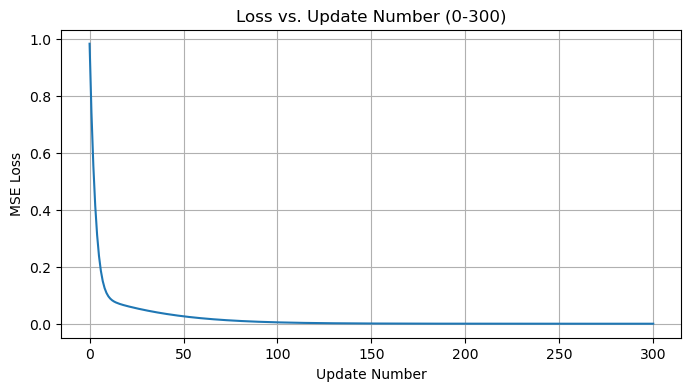


C5. Interpolation Check
Predictions on X_check:
[[1.49961885]
 [0.75136871]
 [0.75136871]
 [1.49961885]]
MSE on X_check: 1.0093159510004993e-06


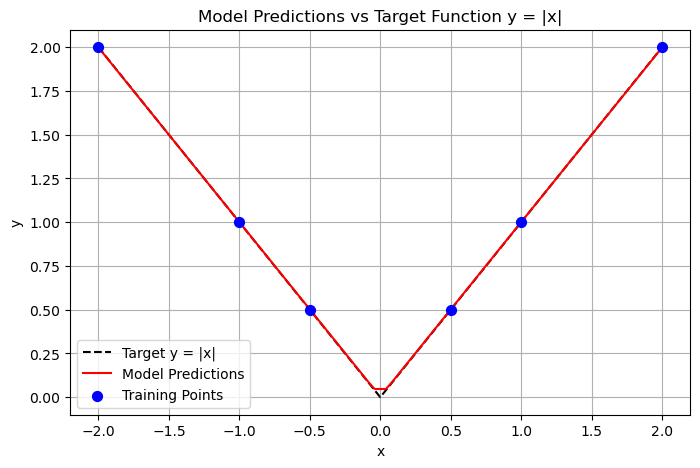

In [ ]:
grads_init = gradients(initial, X, y)
print("C1. Initial Gradients & Shapes Check")
for key in initial:
    match = grads_init[key].shape == initial[key].shape
    print(
        f"d{key} shape: {grads_init[key].shape} | Parameter shape: {initial[key].shape} | Match: {match}"
    )

lr = 0.05
params_step1 = {}
for key in initial:
    params_step1[key] = initial[key] - lr * grads_init[key]
    
print(f"\nLoss before step 1: {mse(initial, X, y)}")
print(f"Loss after step 1:  {mse(params_step1, X, y)}\n")

params = {name: value.copy() for name, value in initial.items()}
history = [mse(params, X, y)]

for step in range(300):
    grads = gradients(params, X, y)
    params = {name: params[name] - lr * grads[name] for name in params}
    history.append(mse(params, X, y))

print("C4. Final Results")
_, _, final_Yhat = forward(params, X)
print(f"Final Predictions Yhat:\n{final_Yhat}")
print(f"Final MSE Loss: {history[-1]:.6f}")

plt.figure(figsize=(8, 4))
plt.plot(history)
plt.title("Loss vs. Update Number (0-300)")
plt.xlabel("Update Number")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

X_check = np.array([[-1.5], [-0.75], [0.75], [1.5]])
y_check = np.abs(X_check)
_, _, Yhat_check = forward(params, X_check)
mse_check = np.mean((Yhat_check - y_check) ** 2)

print("\nC5. Interpolation Check")
print(f"Predictions on X_check:\n{Yhat_check}")
print(f"MSE on X_check: {mse_check}")


X_dense = np.linspace(-2, 2, 101).reshape(-1, 1)
y_dense = np.abs(X_dense)
_, _, Yhat_dense = forward(params, X_dense)

plt.figure(figsize=(8, 5))
plt.plot(X_dense, y_dense, "k--", label="Target y = |x|")
plt.plot(X_dense, Yhat_dense, "r-", label="Model Predictions")
plt.scatter(X, y, color="blue", s=50, zorder=5, label="Training Points")
plt.title("Model Predictions vs Target Function y = |x|")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()